In [ ]:
import os

# Set the backend before importing PyRITE; restart the kernel to change it.
os.environ.setdefault("PYRITE_MC_BACKEND", "cpu")
import marimo as mo  # noqa: F401
import matplotlib.pyplot as plt
import numpy as np

import pyrite

_ = pyrite.fetch_tables()  # Fetch missing pinned tables once; reuse installed data.

tables_ready = True

# Understanding simulation results

[![Open in Molab](https://marimo.io/molab-shield.svg)](https://molab.marimo.io/github/Quantum-Light-Matter-Cooperative-QLMC/pyrite/blob/main/docs/notebooks/02-understanding-results.py)

Convert an electron-normalized PXR/CBS spectrum into a photon rate for
a specified beam current and angular acceptance. A **0.5 pC** bunch at
**100 kHz** gives **50 nA** average current; the **8,192 sampled histories**
are numerical estimators, not bunch electrons.

In [ ]:
from pyrite import simulate
from pyrite.beams import Beam, PointBunch, PointSpot
from pyrite.config import CxrReflections, FixedSampling, Numerics
from pyrite.detectors import Detector
from pyrite.geometry import Footprint, Slab
from pyrite.units import ureg

beam = Beam(
    kinetic_energy=30 * ureg.keV,
    transverse=PointSpot(),
    longitudinal=PointBunch(),
    bunch_charge=0.5 * ureg.pC,
    repetition_rate=100 * ureg.kHz,
)
target = Slab(
    "hopg",
    thickness=100 * ureg.nm,
    tilt=30 * ureg.degree,
    footprint=Footprint(width=5 * ureg.mm, height=5 * ureg.mm),
)
detector = Detector(observation_angle=135 * ureg.degree)
numerics = Numerics(
    sampling=FixedSampling(cxr_electrons=8_192, brem_electrons=128),
    cxr_reflections=CxrReflections(n_families=1),
)
assert tables_ready  # Reference tables must be ready before transport.
result = simulate(beam, target, detector, numerics=numerics)

## Inspect the native spectra

`to_dataframe()` returns a Polars table: one row per energy sample of
one component. `component` identifies CXR, bremsstrahlung or characteristic
radiation; `mode` distinguishes incoherent/coherent CXR (null for other
components). `photon_energy_eV` is in eV, and `density` is in
**photons / (incident electron · eV · sr)**. `normalization="source"`
identifies the source density used here.

Components keep their own energy grids, so rows with the same index need
not describe the same energy. This table has no summed `total`, beam-current
scaling or detector efficiency. Integrating `density` over an energy band
gives photons / (incident electron · sr).

In [ ]:
# Inspect component spectra on their native energy grids.
result.to_dataframe()

component,mode,photon_energy_eV,density,normalization
enum,enum,f64,f64,enum
"""cxr""","""incoherent""",10.0,8.2444e-14,"""source"""
"""cxr""","""incoherent""",10.92574,7.6903e-14,"""source"""
"""cxr""","""incoherent""",11.85148,7.5175e-14,"""source"""
"""cxr""","""incoherent""",12.77722,8.3822e-14,"""source"""
"""cxr""","""incoherent""",13.70296,7.9113e-14,"""source"""
…,…,…,…,…
"""brem""",null,29775.908749,8.8963e-13,"""source"""
"""brem""",null,29850.42483,8.5566e-13,"""source"""
"""brem""",null,29962.508451,2.2299e-13,"""source"""


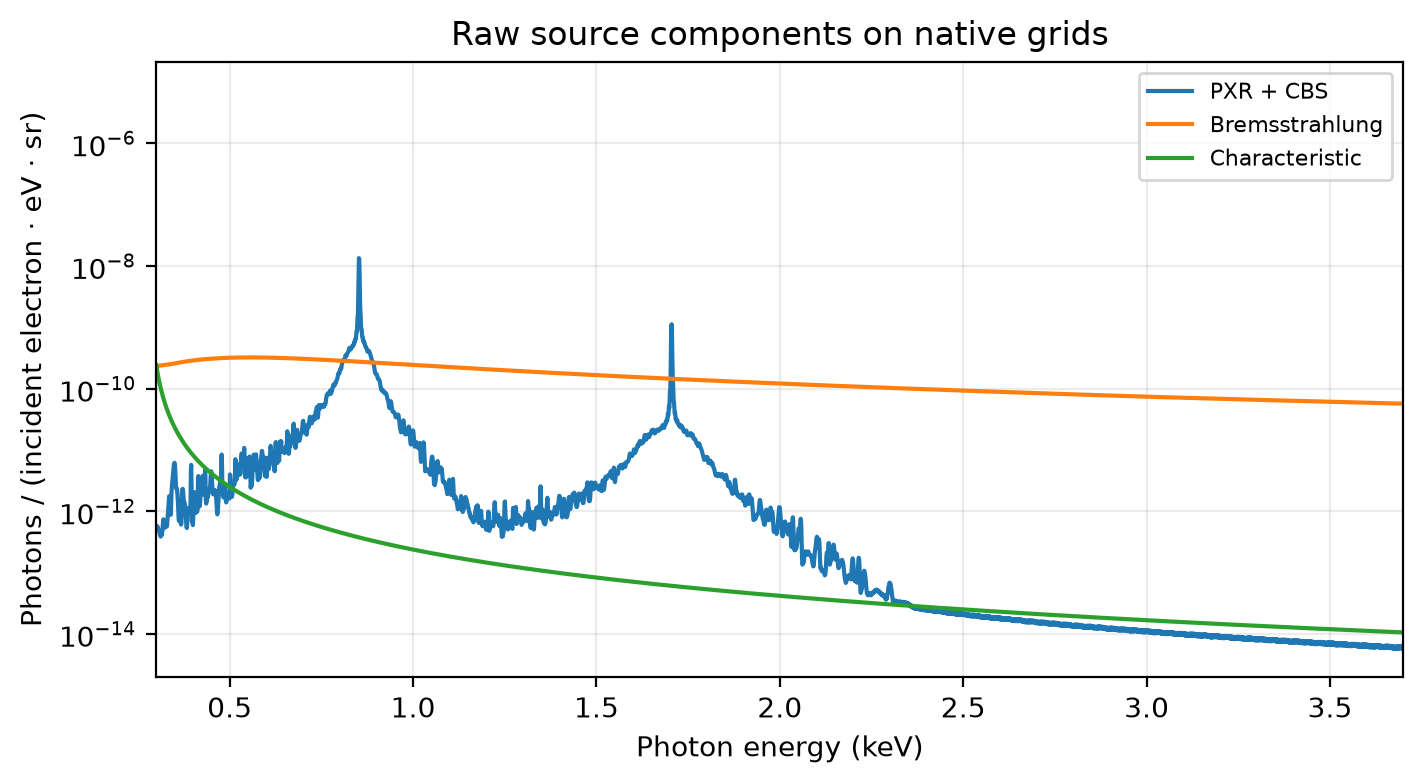

In [ ]:
cxr = result.cxr.incoherent
brem = result.brem
fig_source, ax_source = plt.subplots(figsize=(7, 3.8), layout="constrained")
ax_source.plot(cxr.photon_energy_eV / 1_000, cxr.density, label="PXR + CBS")
ax_source.plot(brem.photon_energy_eV / 1_000, brem.density, label="Bremsstrahlung")
if result.characteristic is not None:
    line = result.characteristic
    ax_source.plot(line.photon_energy_eV / 1_000, line.density, label="Characteristic")
ax_source.set(
    xlabel="Photon energy (keV)",
    ylabel="Photons / (incident electron · eV · sr)",
    title="Raw source components on native grids",
    xlim=(0.3, 3.7),
    yscale="log",
)
ax_source.grid(alpha=0.25)
ax_source.legend(fontsize=8)
fig_source  # noqa: B018 - marimo displays the figure

## Put components on one grid and choose units

`spectral_flux()` returns a wide Polars table: one row per energy, one
column per component, plus `total`. It combines all native energy nodes,
linearly interpolates each component between its nodes, and uses zero
outside that component's range. Columns can now be added at the same energy.

`units` chooses the normalization of **every component and `total`**:

| `units=`               | Spectral values                         | Scaling from `"electron"`          |
| ---------------------- | --------------------------------------- | ---------------------------------- |
| `"electron"`           | photons / (incident electron · eV · sr) | None                               |
| `"sr"`                 | photons / (s · eV · sr)                 | Multiply by physical electrons / s |
| `"detector"` (default) | photons / (s · eV) into acceptance      | Also multiply by accepted sr       |
| `"nA"`                 | photons / (s · nA · eV) into acceptance | Accepted rate per 1 nA of current  |

The energy columns remain in eV and keV; selecting `photon_energy_keV`
does **not** change a density from per eV to per keV (that needs ×1,000).
These are expected rates before detector efficiency and exposure, not
acquired counts. This scalar-detector conversion assumes intensity is
uniform across its accepted solid angle.

In [ ]:
# Each table has a common, interpolated energy grid and explicit units.
per_sr = result.spectral_flux(units="sr")
into_acceptance = result.spectral_flux(units="detector")
into_acceptance  # noqa: B018 - display the common-grid table in marimo

photon_energy_eV,photon_energy_keV,cxr,characteristic,brem,total
f64,f64,f64,f64,f64,f64
10.0,0.01,0.000032,0.000675,0.0,0.000707
10.92574,0.010926,0.00003,0.00068,0.0,0.000709
11.85148,0.011851,0.000029,0.000684,0.0,0.000714
12.77722,0.012777,0.000032,0.000689,0.0,0.000722
13.70296,0.013703,0.000031,0.000694,0.0,0.000725
…,…,…,…,…,…
29775.908749,29.775909,0.0,0.0,0.000344,0.000344
29850.42483,29.850425,0.0,0.0,0.000331,0.000331
29962.508451,29.962508,0.0,0.0,0.000086,0.000086


For this beam, **50 nA ≈ 3.12 × 10¹¹ electrons / s**. Thus the `"sr"`
table is the electron-normalized table multiplied by that rate; the
`"detector"` table also includes the detector's accepted solid angle.
Integrating a `"detector"` column over energy in **eV** gives photons / s.
The following check applies those conversions to the CXR band alone.

In [ ]:
from scipy.constants import elementary_charge

band_eV = (600.0, 2_000.0)
lo, hi = band_eV
energy = cxr.photon_energy_eV
nodes = np.r_[lo, energy[(energy > lo) & (energy < hi)], hi]

# Integrating photon number flux density per electron per sr
cxr_yield_per_electron_sr = float(np.trapezoid(np.interp(nodes, energy, cxr.density), nodes))

current_nA = beam.bunch_charge_pc * beam.rep_rate_hz / 1_000  # Current
electrons_per_second = current_nA * 1e-9 / elementary_charge  # electron number flux density

flux_sr_grid = per_sr.get_column("photon_energy_eV").to_numpy()
flux_sr_cxr = per_sr.get_column("cxr").to_numpy()
cxr_rate_sr = float(np.trapezoid(np.interp(nodes, flux_sr_grid, flux_sr_cxr), nodes))

# For a scalar detector, the accepted rate assumes locally uniform intensity.
result.accepted_solid_angle_sr()
assert np.isclose(cxr_rate_sr, cxr_yield_per_electron_sr * electrons_per_second, rtol=1e-10)
assert np.array_equal(into_acceptance.get_column("photon_energy_eV").to_numpy(), flux_sr_grid)

### Plot the complete spectrum summed over all components

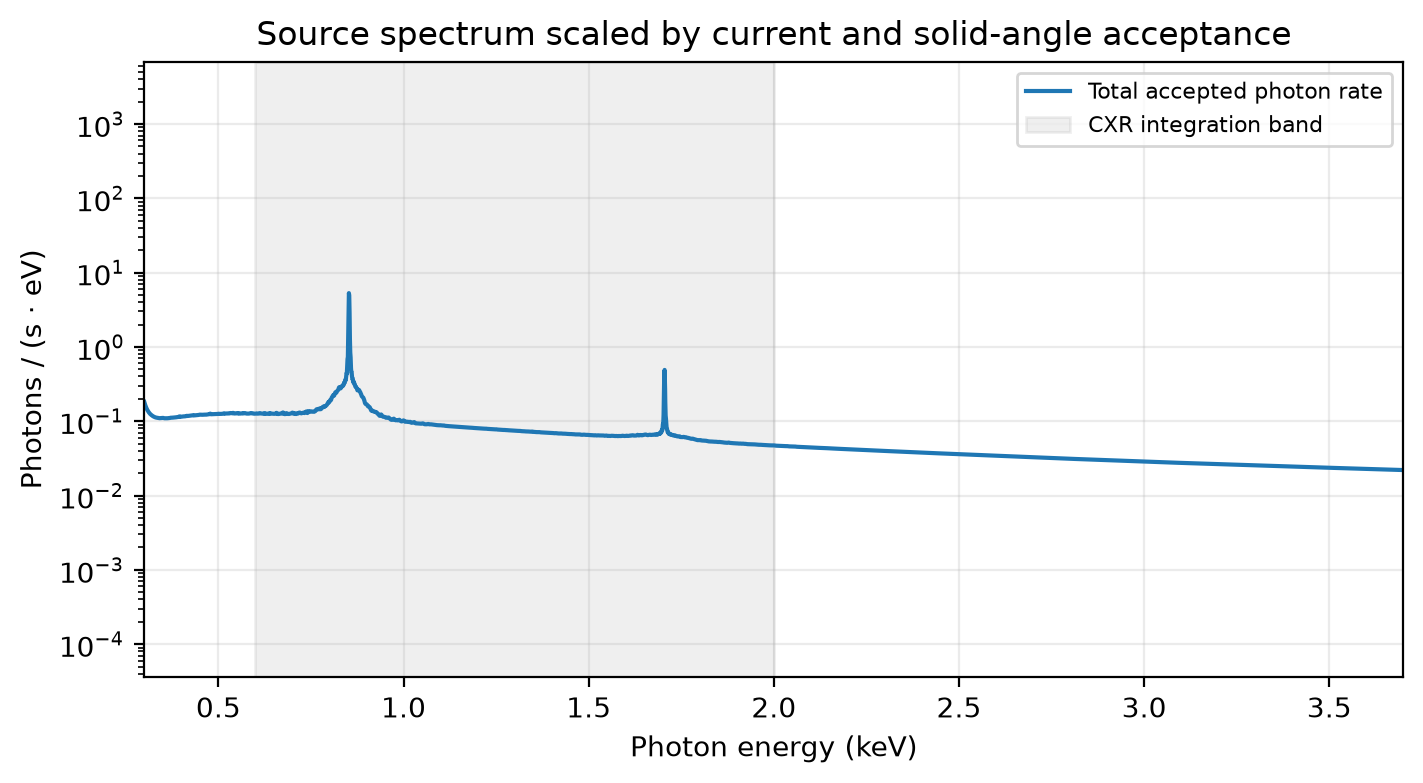

In [ ]:
fig_rate, ax_rate = plt.subplots(figsize=(7, 3.8), layout="constrained")
ax_rate.plot(
    into_acceptance.get_column("photon_energy_eV").to_numpy() / 1_000,
    into_acceptance.get_column("total").to_numpy(),
    label="Total accepted photon rate",
)
ax_rate.axvspan(0.6, 2.0, alpha=0.12, color="grey", label="CXR integration band")
ax_rate.set(
    xlabel="Photon energy (keV)",
    ylabel="Photons / (s · eV)",
    title="Source spectrum scaled by current and solid-angle acceptance",
    xlim=(0.3, 3.7),
    yscale="log",
)
ax_rate.grid(alpha=0.25)
ax_rate.legend(fontsize=8)
fig_rate  # noqa: B018 - marimo displays the figure

## Interpretation

`to_dataframe()` preserves each component's native energy grid;
`spectral_flux()` interpolates onto a common one. `"electron"` gives
the electron-normalized density, `"sr"` scales by the physical electron
rate, and `"detector"` also multiplies by accepted solid angle.

The **600–2,000 eV** band integral uses CXR only; the photon-rate plot
includes all computed components. These are _expected source rates_,
not measured counts: no exposure, efficiency or Poisson noise is applied.
The scalar acceptance assumes locally uniform angular density.

Try doubling `bunch_charge_pc` without changing the history count.
Notebook 06 adds detector response and counts. See the
[results how-to](https://pyrite.readthedocs.io/en/latest/guides/working-with-results.html)
for saving and reloading results.

## Continue learning

Next: [Predicting PXR line energies](03-pxr-line-energies.ipynb).
Use [Working with results](../../guides/working-with-results.md) to inspect saved
calculations and the [results API](../../reference/python-api/results.md) for
analysis interfaces. [Spectral observables](../../physics/radiation-physics/spectral-observables.md)
and [energy-grid semantics](../../physics/radiation-physics/energy-grid-semantics.md)
explain the units and integration conventions used here.

{download}`Download canonical Marimo notebook <../02-understanding-results.py>`